In [2]:
import os, cv2
import numpy as np
from glob import glob
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
path = '../../../../Datasets/Processed/Oslo_processed'
video_path = os.path.join(path, 'videos')
excel_path = os.path.join(path, 'Oslo_completo.xlsx')

In [4]:
X_train = os.listdir(video_path)

In [5]:
df = pd.read_excel(excel_path)
df

,Embryo_id,HCG Test,IVF/ICSI,Fetal_Heart_Beat,ID,Well,End Time,Fertilization,Runs,Start Time,...,Nuclei - Time,Nuclei - Value,Pronuclei - Time,Pronuclei - Value,Inner Cell Mass - Time,Inner Cell Mass - Value,Trophectoderm Evaluation - Time,Trophectoderm Evaluation - Value,Tse,frame_hour
0,1,0,ivf,0,D2016.05.05_S0546_I427,1,42503.49028,42494.59722,583,42495.40129,...,26.32529667,1,19.32242917,2,,,,,19.29768,3.0
1,4,1,ivf,0,D2016.05.14_S0631_I426,4,42509.44539,42503.62500,484,42504.40882,...,53.86002472,3,19.10020917,2,,,,,18.81168,4.0
2,2,0,ivf,0,D2016.05.20_S0552_I427,2,42514.45957,42509.55208,287,42510.48947,...,27.85637167,2,,,,,,,22.49736,3.0
3,6,0,icsi,0,D2016.05.25_S0554_I427,6,42520.44049,42515.55208,350,42515.58159,...,39.51873278,4,14.09637722,2,,,,,0.70824,3.0
4,1,1,ivf,1,D2016.05.28_S0640_I426,1,42522.44506,42517.57639,388,42518.39973,...,27.86531556,1,19.86121833,2,,,,,19.76016,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
446,3,0,icsi,0,D2019.05.16_S01297_I0427_D,3,43605.40605,43601.54861,792,43601.55038,...,33.414829,2,17.458099,2,NaN,NaN,NaN,NaN,0.04248,8.6
447,1,1,ivf,1,D2019.05.17_S01299_I0427_D,1,43605.41078,43601.57986,638,43602.30562,...,35.338381,2,NaN,NaN,NaN,NaN,NaN,NaN,17.41824,8.6
448,2,1,icsi,0,D2019.05.16_S01396_I0426_D,2,43606.43925,43601.60417,461,43601.63385,...,45.0301,1,16.020072,2,NaN,NaN,NaN,NaN,0.71232,4.0
449,2,0,icsi,0,D2019.05.15_S01392_I0426_D,2,43605.41252,43600.57292,463,43600.58583,...,69.565035,3,17.837206,2,NaN,NaN,NaN,NaN,0.30984,4.0


In [6]:
len(X_train)

451

In [7]:
y_train = []
for video in X_train:
    id, well = video.split('_Well_')
    well = int(well.split('.')[0])
    y_train.append(int(df[(df['ID'] == id) & (df['Well'] == well)]['Fetal_Heart_Beat'].values[0]))

FRAME SELECTION

In [8]:
vid = 0
print(X_train[vid])
data = df[(df['ID'] == X_train[vid].split('_Well')[0]) ]
video = cv2.VideoCapture(os.path.join(video_path, X_train[vid]))
fps = video.get(cv2.CAP_PROP_FPS)

D2017.10.30_S00906_I0427_D_Well_05.avi


In [9]:
total_time = 24*(data['End Time'] - data['Start Time'])

In [10]:
total_time/24

215    3.87982
dtype: float64

In [11]:
frames = total_time * data['frame_hour']
frames

215    791.48328
dtype: float64

In [12]:
frames/fps

215    79.148328
dtype: float64

In [13]:
time = data.t3 - data.Tse
frame = time * data['frame_hour']
print(time)
frame

215    33.172361
dtype: object


215    281.965067
dtype: object

In [14]:
all_frames = []
ret = True
while ret:
    ret, frame = video.read()
    if ret:
        all_frames.append(frame)

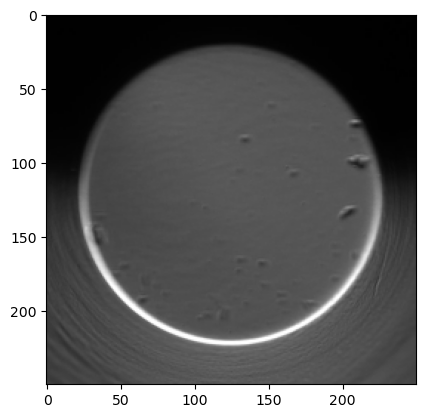

In [15]:
plt.imshow(all_frames[42])

In [24]:
TIME_window = [i for i in range(0, 24*5, 4)]
video_dataset = []
mask_dataset = []
for i,video in enumerate(X_train):
    video_dataset.append([])
    mask_dataset.append([])
    id, well = video.split('_Well_')
    well = int(well.split('.')[0])
    data = df[(df['ID'] == id) & (df['Well'] == well)]
    cap = cv2.VideoCapture(os.path.join(video_path, video))
    for time in TIME_window:
        frame =int((time - data['Tse'])* data['frame_hour'])
        if frame < 0:
            video_dataset[i].append(np.zeros((250,250,3)))
            mask_dataset[i].append(1) 
            continue
        #set video to frame
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame))
        ret, img = cap.read()
        if ret:
            video_dataset[i].append(img)
            mask_dataset[i].append(0)
        else:
            video_dataset[i].append(np.zeros((250,250,3)))
            mask_dataset[i].append(1) 

/tmp/ipykernel_3472935/1933105585.py:12: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  frame =int((time - data['Tse'])* data['frame_hour'])


In [25]:
len(TIME_window)

30

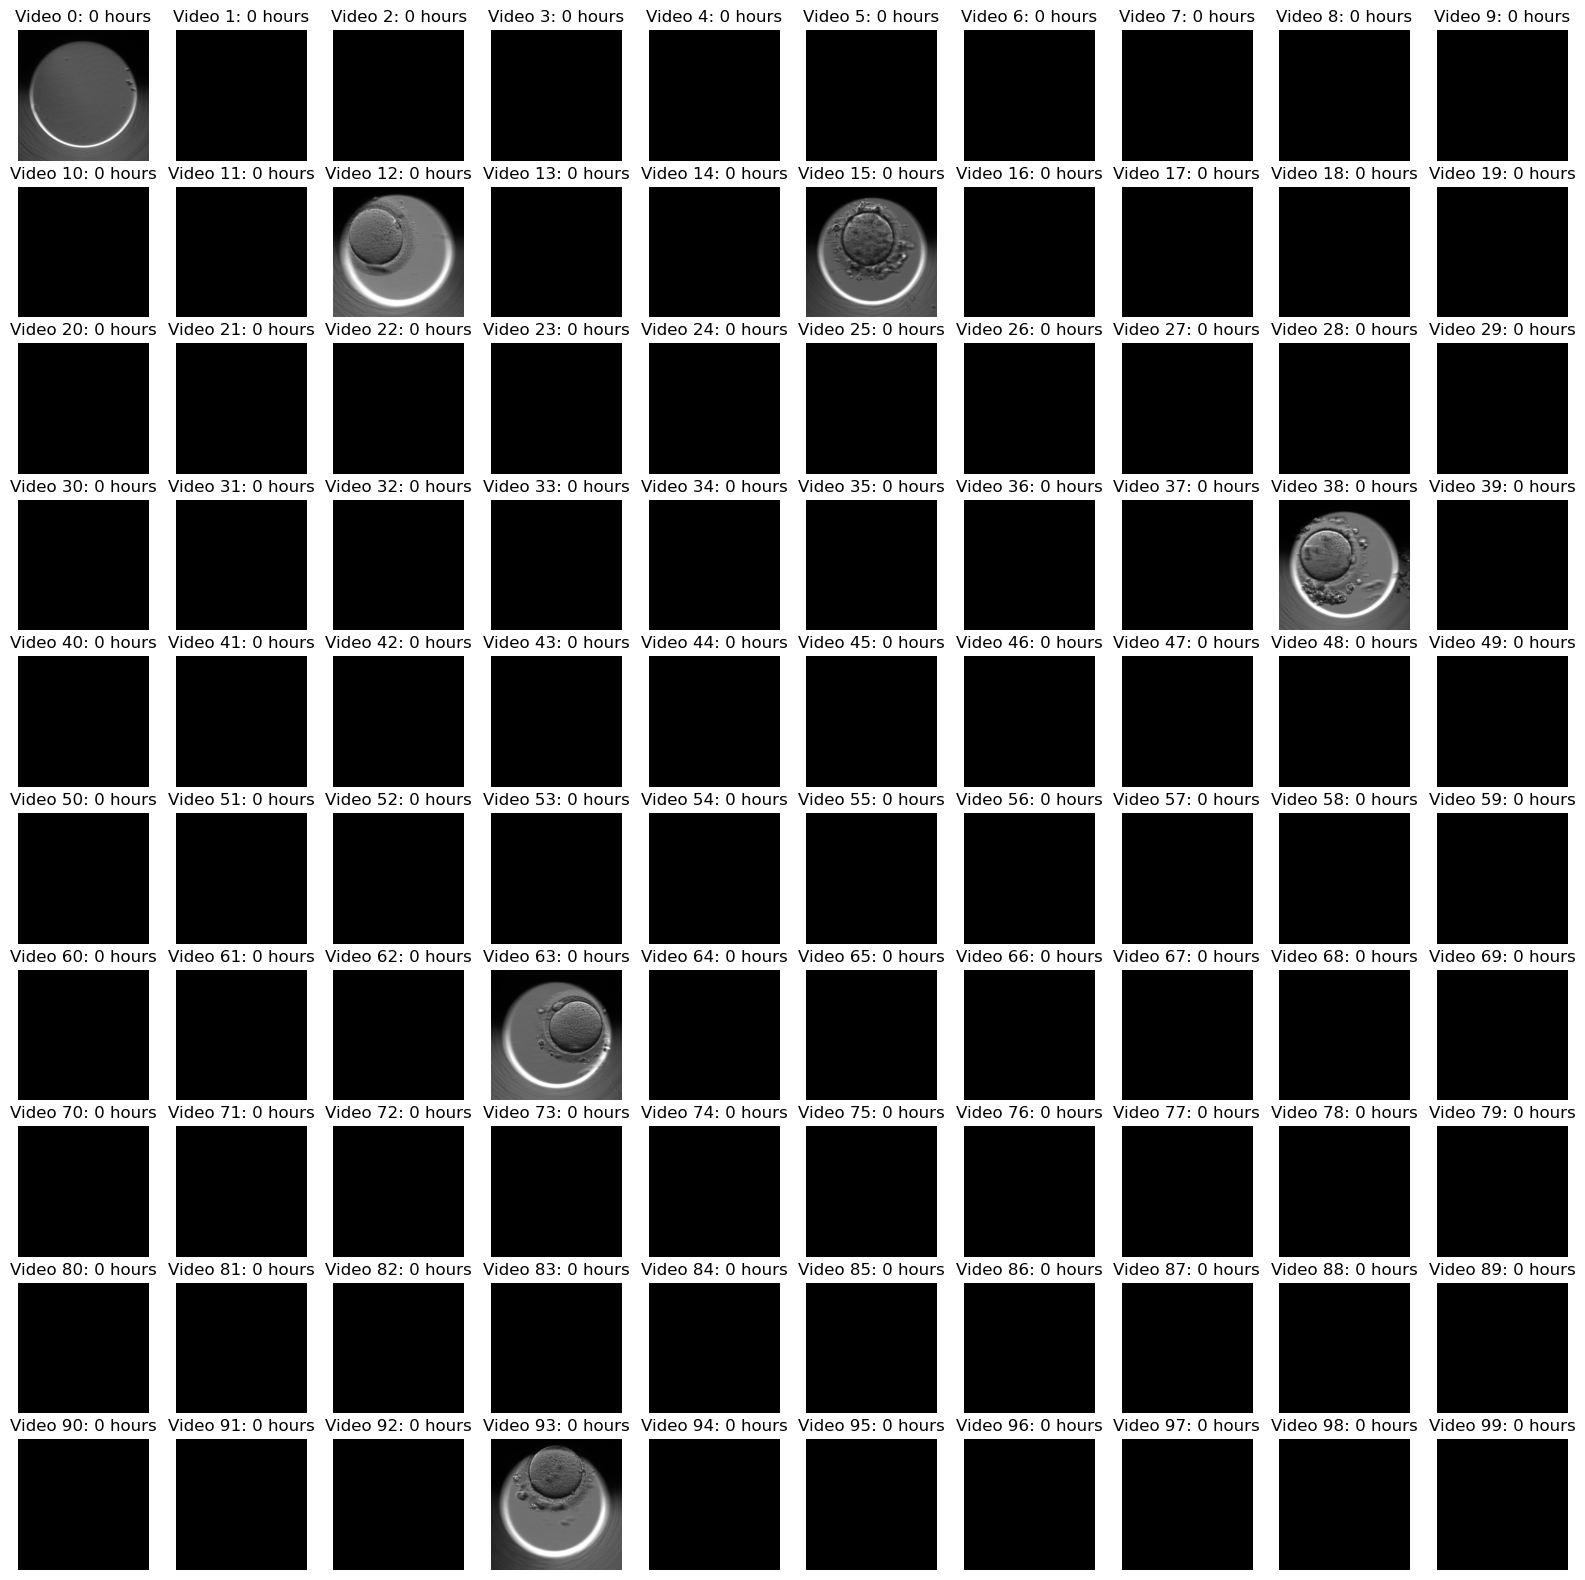

In [19]:
time = 0
#plot different figures in one figure
fig, axs = plt.subplots(10,10, figsize=(20, 20))
for i in range(10):
    for j in range(10):
        axs[i, j].imshow(video_dataset[i*10+j][time])
        axs[i, j].set_title(f'Video {i*10+j}: {TIME_window[time]} hours')
        axs[i, j].axis('off')
plt.show()

In [20]:
df.head()

,Embryo_id,HCG Test,IVF/ICSI,Fetal_Heart_Beat,ID,Well,End Time,Fertilization,Runs,Start Time,...,Nuclei - Time,Nuclei - Value,Pronuclei - Time,Pronuclei - Value,Inner Cell Mass - Time,Inner Cell Mass - Value,Trophectoderm Evaluation - Time,Trophectoderm Evaluation - Value,Tse,frame_hour
0,1,0,ivf,0,D2016.05.05_S0546_I427,1,42503.49028,42494.59722,583,42495.40129,...,26.32529667,1,19.32242917,2,,,,,19.29768,3.0
1,4,1,ivf,0,D2016.05.14_S0631_I426,4,42509.44539,42503.62500,484,42504.40882,...,53.86002472,3,19.10020917,2,,,,,18.81168,4.0
2,2,0,ivf,0,D2016.05.20_S0552_I427,2,42514.45957,42509.55208,287,42510.48947,...,27.85637167,2,,,,,,,22.49736,3.0
3,6,0,icsi,0,D2016.05.25_S0554_I427,6,42520.44049,42515.55208,350,42515.58159,...,39.51873278,4,14.09637722,2,,,,,0.70824,3.0
4,1,1,ivf,1,D2016.05.28_S0640_I426,1,42522.44506,42517.57639,388,42518.39973,...,27.86531556,1,19.86121833,2,,,,,19.76016,4.0


In [21]:
frames = np.array(df['Runs'])
print(min(frames), max(frames))

4 1594


In [22]:
dias = np.array(df['End Time'] - df['Start Time'])
print(min(dias), max(dias))

0.020109999997657724 8.088989999996556


In [23]:
np.unique(dias < 3, return_counts=True)

(array([False,  True]), array([380,  71]))

In [27]:
np.unique(y_train, return_counts=True)

(array([0, 1]), array([266, 185]))

In [28]:
len(y_train)

451